# Klasifikacija znakov kamen, škarje, papir s konvolucijskimi nevronskimi mrežami (CNN)

V zvezku pripravimo cevovod za obdelavo sivinskih slik znakov kamen (`Rock`), papir (`Paper`) in škarje (`Scissors`), razvijemo ter primerjamo štiri postopno nadgrajene arhitekture CNN od začetka (*from scratch*) na enaki stratificirani delitvi, na podlagi validacijske utežene F1-vrednosti izberemo najboljši model, ga shranimo ter pripravimo napovedi za testno množico.

Uvozimo potrebne knjižnice za delo z datotekami, tabelami, slikami, nevronskimi mrežami in metrikami ter nastavimo seme naključnih števil in velikost vhodnih slik.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

SEED = 1234
IMG_SIZE = 80
DATA_DIR = 'rirsu-2026-klasifikacija'
tf.keras.utils.set_random_seed(SEED)

## 1. Pregled podatkovne zbirke

Zberemo poti do učnih slik in njihove oznake v preglednico `DataFrame`, preverimo število primerov ter izvorne dimenzije slik v posameznem razredu in prikažemo porazdelitev razredov.

Stevilo ucnih slik: 3150
label
Paper       1028
Rock        1050
Scissors    1072
Name: count, dtype: int64

Najpogostejse izvorne dimenzije slik: {(100, 56): 1235, (75, 100): 855, (100, 100): 462, (56, 100): 264, (100, 176): 139, (100, 59): 25}


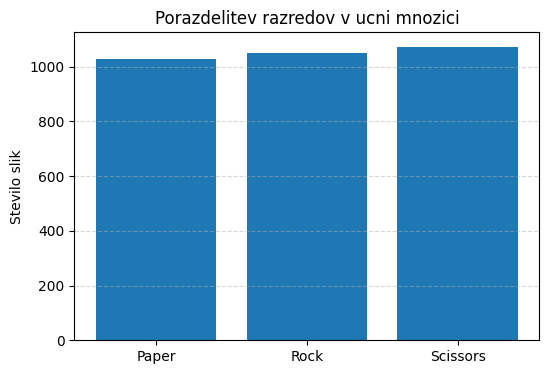

In [2]:
class_names = ['Paper', 'Rock', 'Scissors']
train_dir = os.path.join(DATA_DIR, 'train')

records = []
sizes = []
for label in class_names:
    cls_dir = os.path.join(train_dir, label)
    for fname in sorted(os.listdir(cls_dir)):
        if fname.lower().endswith('.jpg'):
            fpath = os.path.join(cls_dir, fname)
            records.append({'filepath': fpath, 'label': label})
            with Image.open(fpath) as im:
                sizes.append(im.size)

train_df = pd.DataFrame(records)
counts = train_df['label'].value_counts().reindex(class_names)
print('Stevilo ucnih slik:', len(train_df))
print(counts)
print('\nNajpogostejse izvorne dimenzije slik:', pd.Series(sizes).value_counts().head(6).to_dict())

plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values)
plt.title('Porazdelitev razredov v ucni mnozici')
plt.ylabel('Stevilo slik')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

Prikažemo po štiri vzorčne slike iz vsakega razreda, da preverimo raznolikost ozadij, osvetlitve in razmerij stranic.

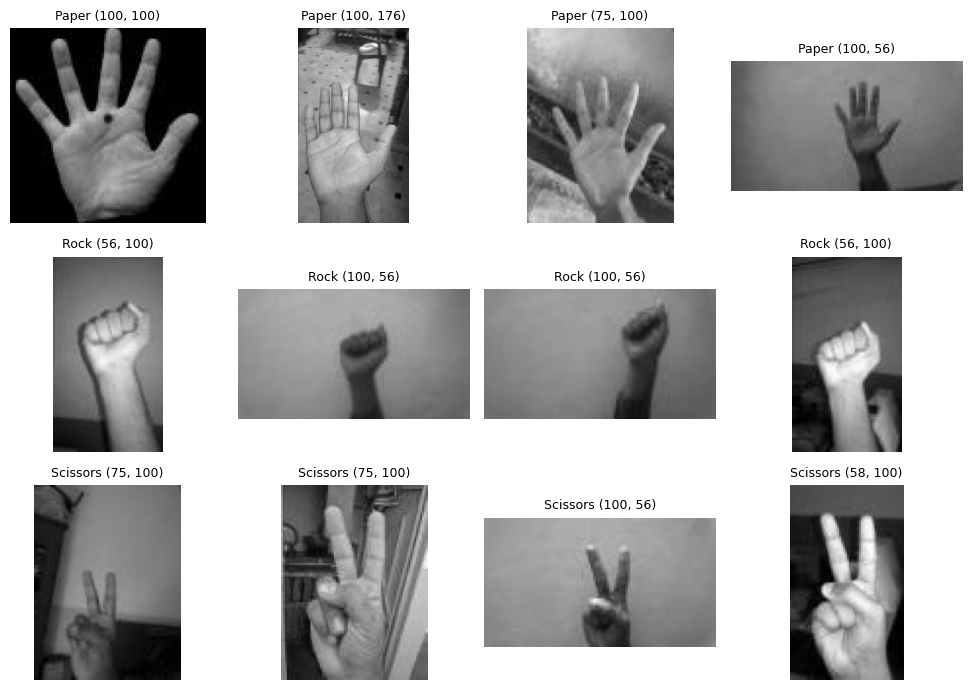

In [3]:
fig, axes = plt.subplots(len(class_names), 4, figsize=(10, 7))
for row, label in enumerate(class_names):
    subset = train_df[train_df['label'] == label]['filepath'].to_numpy()
    pick = np.linspace(0, len(subset) - 1, 4, dtype=int)
    for col, idx in enumerate(pick):
        with Image.open(subset[idx]) as im:
            axes[row, col].imshow(im, cmap='gray', vmin=0, vmax=255)
            axes[row, col].set_title(f'{label} {im.size}', fontsize=9)
            axes[row, col].axis('off')
plt.tight_layout()
plt.show()

## 2. Predobdelava, delitev podatkov in cevovod `tf.data.Dataset`

Oznake preslikamo v števila (`Paper: 0, Rock: 1, Scissors: 2`), učno zbirko stratificirano razdelimo na učno (80 %) in validacijsko (20 %) množico ter pripravimo cevovod `tf.data.Dataset` s sivinskim dekodiranjem, ohranjanjem razmerja stranic (`resize_with_pad`) in normalizacijo na `[0, 1]`.

In [4]:
label_to_idx = {name: i for i, name in enumerate(class_names)}
idx_to_label = {i: name for i, name in enumerate(class_names)}

paths = train_df['filepath'].to_numpy()
y = train_df['label'].map(label_to_idx).to_numpy(dtype=np.int32)

# enaka stratificirana delitev 80/20 (2520 ucnih / 630 validacijskih) za vse eksperimente
train_paths, val_paths, y_train, y_val = train_test_split(
    paths, y, test_size=0.2, stratify=y, random_state=SEED
)

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=1)  # sivinska slika (1 kanal)
    img = tf.image.resize_with_pad(img, IMG_SIZE, IMG_SIZE)  # ohrani razmerje stranic prstov brez raztezanja
    img = img / 255.0  # normalizacija na [0, 1]
    return img, label

def make_dataset(file_paths, labels, batch_size=32, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((file_paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.cache()  # slike ostanejo v RAM-u po 1. epohi za hitrejse ucenje
    if shuffle:
        ds = ds.shuffle(len(file_paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_paths, y_train, batch_size=32, shuffle=True)
val_ds = make_dataset(val_paths, y_val, batch_size=32, shuffle=False)

sample_x, sample_y = next(iter(train_ds))
print(f'Ucenje: {len(train_paths)} slik, Validacija: {len(val_paths)} slik')
print('Oblika paketka:', sample_x.shape, sample_x.dtype)
print('Obseg vrednosti:', float(tf.reduce_min(sample_x)), '-', float(tf.reduce_max(sample_x)))

Ucenje: 2520 slik, Validacija: 630 slik
Oblika paketka: (32, 80, 80, 1) <dtype: 'float32'>
Obseg vrednosti: 0.0 - 1.0


## 3. Podatkovna augmentacija

Definiramo sklop naključnih transformacij (vodoravno zrcaljenje, zmerna rotacija, povečava, premik in kontrast), ki ohranjajo pravilen razred znaka ter se uporabljajo izključno med učenjem, nato pa prikažemo primerjavo izvirnih in augmentiranih slik.

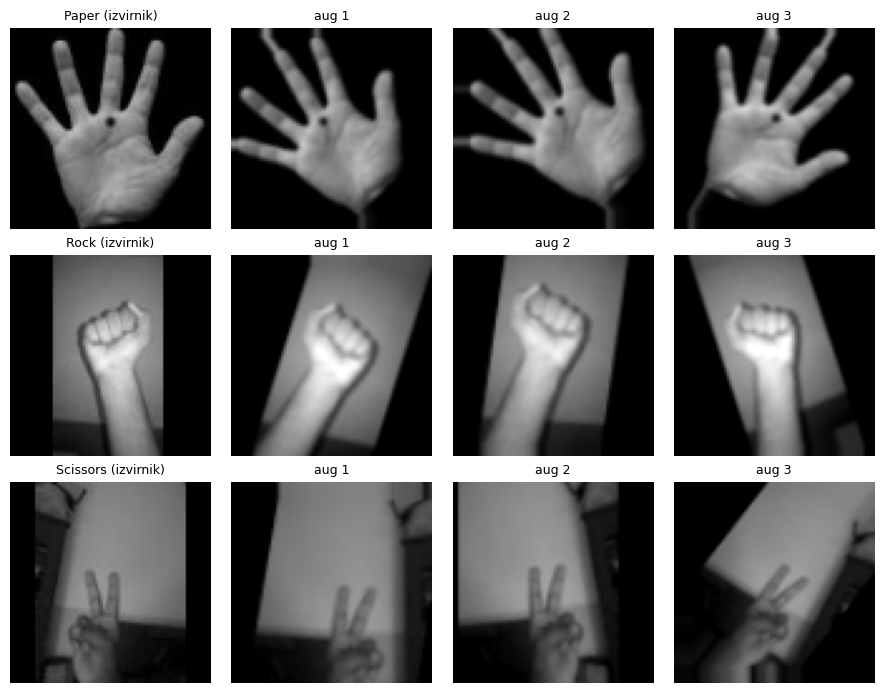

In [5]:
def make_augmentation():
    return keras.Sequential([
        layers.RandomFlip('horizontal'),  # leva <-> desna roka
        layers.RandomRotation(0.12, fill_mode='nearest'),  # 'nearest' zapolni rob z barvo najblizjega roba
        layers.RandomZoom(0.12, fill_mode='nearest'),  # razlicna oddaljenost dlani
        layers.RandomTranslation(0.08, 0.08, fill_mode='nearest'),  # razlicni polozaji v kadru
        layers.RandomContrast(0.2, value_range=(0, 1)),  # prilagoditev svetlosti znotraj [0, 1]
    ], name='augmentation')

aug_preview = make_augmentation()
fig, axes = plt.subplots(len(class_names), 4, figsize=(9, 7))
for row, label in enumerate(class_names):
    path = train_df.loc[train_df['label'] == label, 'filepath'].iloc[0]
    img, _ = load_image(path, 0)
    axes[row, 0].imshow(img[:, :, 0], cmap='gray', vmin=0, vmax=1)
    axes[row, 0].set_title(f'{label} (izvirnik)', fontsize=9)
    axes[row, 0].axis('off')
    for col in range(1, 4):
        aug_img = aug_preview(img[None, ...], training=True)[0]
        axes[row, col].imshow(aug_img[:, :, 0], cmap='gray', vmin=0, vmax=1)
        axes[row, col].set_title(f'aug {col}', fontsize=9)
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

## 4. Eksperimentalni razvoj in vrednotenje modelov

Pripravimo pomožno funkcijo za ponovljivo učenje in izračun validacijskih metrik (`Accuracy`, `Weighted Precision`, `Weighted Recall` in `Weighted F1-score`) nad enako delitvijo podatkov.

In [6]:
experiments = {}

def run_experiment(name, build_fn, epochs, callbacks, note):
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_fn()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        callbacks=callbacks,
        verbose=0,
        shuffle=False,
    )
    y_pred = np.argmax(model.predict(val_ds, verbose=0), axis=1)
    metrics = {
        'Konfiguracija': name,
        'Sprememba': note,
        'Parametri': model.count_params(),
        'Epoh': len(history.history['loss']),
        'Accuracy': accuracy_score(y_val, y_pred),
        'Weighted Precision': precision_score(y_val, y_pred, average='weighted', zero_division=0),
        'Weighted Recall': recall_score(y_val, y_pred, average='weighted', zero_division=0),
        'Weighted F1-score': f1_score(y_val, y_pred, average='weighted', zero_division=0),
    }
    experiments[name] = {
        'model': model,
        'history': history.history,
        'metrics': metrics,
        'y_pred': y_pred,
    }
    print(f"{name}: parametri={metrics['Parametri']:,}, epoh={metrics['Epoh']}, "
          f"Accuracy={metrics['Accuracy']:.4f}, Weighted F1={metrics['Weighted F1-score']:.4f}")

### Eksperiment 1: Osnovni CNN (brez augmentacije in regularizacije)

Zgradimo preprosto izhodiščno arhitekturo s tremi konvolucijskimi bloki (`32 -> 64 -> 128` filtrov, `3x3`, `padding='same'`, `relu`), plastmi `MaxPooling2D(2x2)`, sploščitvijo `Flatten` in polno povezanim slojem `Dense(128)`. Uporabimo optimizator `Adam(1e-3)` in največ 50 epoh z zgodnjim ustavljanjem (`patience=10`).

In [7]:
def build_exp1():
    model = keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
        layers.Conv2D(32, 3, padding='same', activation='relu'),  # osnovna izhodiscna arhitektura
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.Flatten(),  # splosci 10x10x128 v 12.800 znacilk
        layers.Dense(128, activation='relu'),
        layers.Dense(3, activation='softmax'),
    ], name='exp1_osnovni_cnn')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

run_experiment(
    'Exp 1: Osnovni CNN',
    build_exp1,
    epochs=50,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)],
    note='Izhodiscna 3-slojna arhitektura brez augmentacije',
)

Exp 1: Osnovni CNN: parametri=1,731,587, epoh=22, Accuracy=0.9873, Weighted F1=0.9873


### Eksperiment 2: Osnovni CNN s podatkovno augmentacijo

Glede na Eksperiment 1 ohranimo enako konvolucijsko arhitekturo in optimizator `Adam(1e-3)`, dodamo pa cevovod podatkovne augmentacije na začetek modela ter podaljšamo največje število epoh na 60 (`patience=12`), da model izkoristi razširjeno raznolikost učnih primerov.

In [8]:
def build_exp2():
    model = keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
        make_augmentation(),  # edina sprememba proti Exp 1: augmentacija med ucenjem
        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(3, activation='softmax'),
    ], name='exp2_osnovni_aug')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

run_experiment(
    'Exp 2: Osnovni + augmentacija',
    build_exp2,
    epochs=60,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True)],
    note='+ podatkovna augmentacija (Flip, Rot, Zoom, Trans, Contrast)',
)

Exp 2: Osnovni + augmentacija: parametri=1,731,587, epoh=58, Accuracy=0.9905, Weighted F1=0.9905


### Eksperiment 3: 4-blokovni CNN z `BatchNormalization`, `GlobalAveragePooling2D` in regularizacijo

Glede na Eksperiment 2 dodamo četrti konvolucijski blok (`256` filtrov) in `BatchNormalization` pred aktivacijo `ReLU`, namesto `Flatten` uporabimo `GlobalAveragePooling2D` za zmanjšanje števila parametrov, dodamo regularizacijo `Dropout(0.4 / 0.3)` ter `L2(1e-4)` in vključimo `ReduceLROnPlateau` (`epochs=80`, `patience=15`).

In [9]:
def build_exp3():
    model = keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
        make_augmentation(),
        layers.Conv2D(32, 3, padding='same', use_bias=False),  # use_bias=False, ker premik doda BatchNormalization
        layers.BatchNormalization(),  # stabilizira razlicne svetlosti fotografij
        layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(256, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),  # 4x MaxPooling skrci 80 -> 5x5
        layers.GlobalAveragePooling2D(),  # vsak filter povpreci v 1 stevilo (256 znacilk namesto Flatten)
        layers.Dropout(0.4),
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),  # Dropout + L2 proti preprileganju
        layers.Dropout(0.3),
        layers.Dense(3, activation='softmax'),
    ], name='exp3_bn_gap_reg')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

run_experiment(
    'Exp 3: 4-blokovni BN + GAP + Reg',
    build_exp3,
    epochs=80,
    callbacks=[
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5),  # prepolovi lr ob zastoju
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
    ],
    note='4 bloki + BatchNorm + GAP + Dropout(0.4/0.3) + L2 + ReduceLROnPlateau',
)

Exp 3: 4-blokovni BN + GAP + Reg: parametri=422,563, epoh=66, Accuracy=0.9429, Weighted F1=0.9429


### Eksperiment 4: Globlji CNN z dvojnimi konvolucijskimi bloki, `SpatialDropout2D` in `AdamW`

Glede na Eksperiment 3 povečamo globino z dvojnimi `3x3` konvolucijskimi sloji v blokih 2, 3 in 4 za večje receptivno polje, dodamo prostorsko regularizacijo `SpatialDropout2D(0.1 / 0.15)` in zamenjamo optimizator z `AdamW(learning_rate=1e-3, weight_decay=1e-4)` (`epochs=100`, `patience=15`).

In [10]:
def build_exp4():
    model = keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
        make_augmentation(),
        layers.Conv2D(32, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),  # 80 -> 40

        # dvojna 3x3 konvolucija zajame vecje okolje prstov kot ena sama
        layers.Conv2D(64, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(64, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),  # 40 -> 20
        layers.SpatialDropout2D(0.1),  # izklopi celotne 2D filtre namesto posameznih pikslov

        layers.Conv2D(128, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(128, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),  # 20 -> 10
        layers.SpatialDropout2D(0.15),

        layers.Conv2D(256, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(256, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.GlobalAveragePooling2D(),  # ohrani 10x10 locljivost pred povprecenjem

        layers.Dropout(0.4),
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.3),
        layers.Dense(3, activation='softmax'),
    ], name='exp4_dvojni_adamw')
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),  # loceno upadanje utezi (weight decay)
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

run_experiment(
    'Exp 4: Dvojni bloki + AdamW',
    build_exp4,
    epochs=100,
    callbacks=[
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-5),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
    ],
    note='Dvojni Conv2D bloki + SpatialDropout2D + AdamW',
)

Exp 4: Dvojni bloki + AdamW: parametri=1,198,499, epoh=80, Accuracy=0.9968, Weighted F1=0.9968


## 5. Primerjava učnih krivulj in rezultatov

Izrišemo krivulji učne in validacijske točnosti ter funkcije izgube za vse štiri eksperimente.

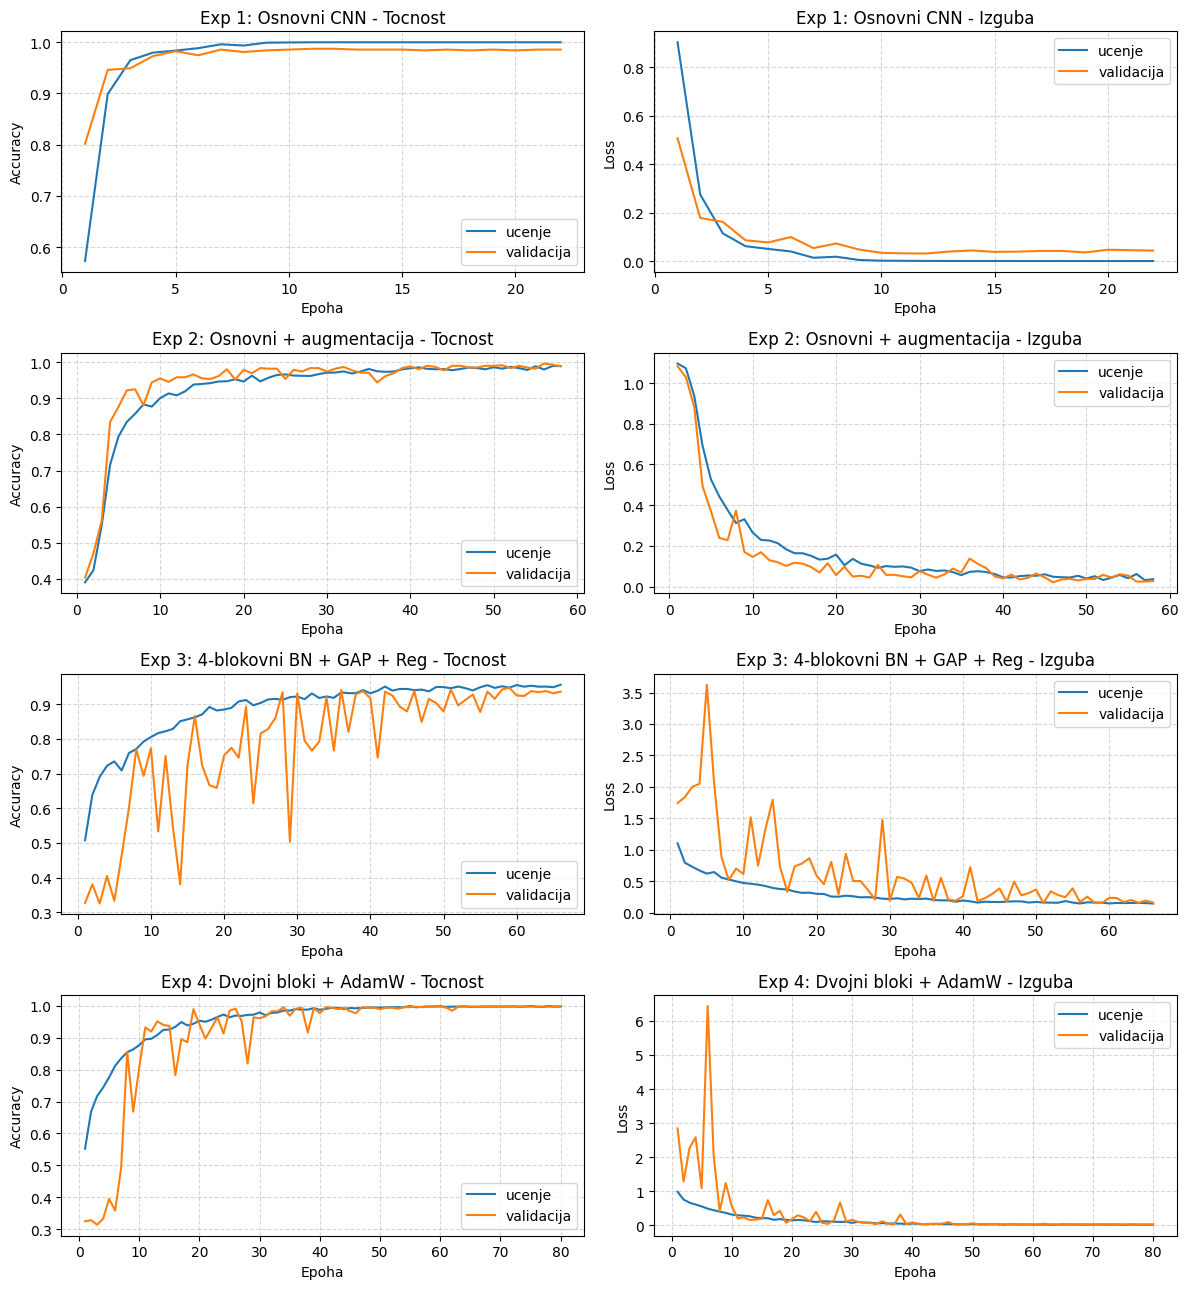

In [11]:
fig, axes = plt.subplots(len(experiments), 2, figsize=(12, 13))
for row, (name, exp) in enumerate(experiments.items()):
    hist = exp['history']
    ep_range = range(1, len(hist['loss']) + 1)

    axes[row, 0].plot(ep_range, hist['accuracy'], label='ucenje')
    axes[row, 0].plot(ep_range, hist['val_accuracy'], label='validacija')
    axes[row, 0].set_title(f'{name} - Tocnost')
    axes[row, 0].set_xlabel('Epoha')
    axes[row, 0].set_ylabel('Accuracy')
    axes[row, 0].legend()
    axes[row, 0].grid(True, linestyle='--', alpha=0.5)

    axes[row, 1].plot(ep_range, hist['loss'], label='ucenje')
    axes[row, 1].plot(ep_range, hist['val_loss'], label='validacija')
    axes[row, 1].set_title(f'{name} - Izguba')
    axes[row, 1].set_xlabel('Epoha')
    axes[row, 1].set_ylabel('Loss')
    axes[row, 1].legend()
    axes[row, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Zberemo vse metrike v primerjalno tabelo, grafično primerjamo doseženo uteženo F1-vrednost ter za zmagovalni model izrišemo matriko zmede na validacijski množici in povzetek arhitekture.

,Konfiguracija,Sprememba,Parametri,Epoh,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-score
0,Exp 1: Osnovni CNN,Izhodiscna 3-slojna arhitektura brez augmentacije,1731587,22,0.9873,0.9875,0.9873,0.9873
1,Exp 2: Osnovni + augmentacija,"+ podatkovna augmentacija (Flip, Rot, Zoom, Tr...",1731587,58,0.9905,0.9905,0.9905,0.9905
2,Exp 3: 4-blokovni BN + GAP + Reg,4 bloki + BatchNorm + GAP + Dropout(0.4/0.3) +...,422563,66,0.9429,0.9455,0.9429,0.9429
3,Exp 4: Dvojni bloki + AdamW,Dvojni Conv2D bloki + SpatialDropout2D + AdamW,1198499,80,0.9968,0.9968,0.9968,0.9968


Izbrani koncni model: Exp 4: Dvojni bloki + AdamW (Weighted F1 = 0.9968)


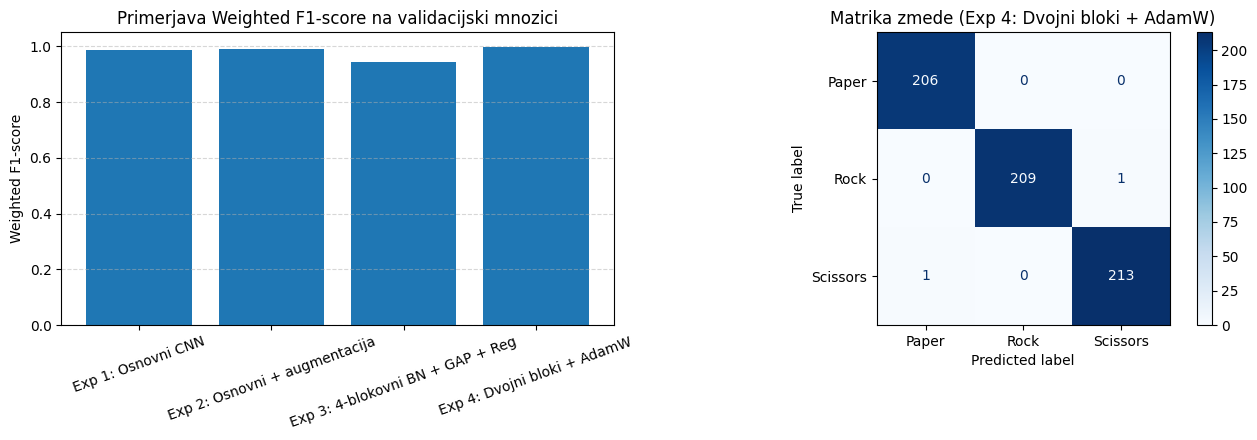

Model: "exp4_dvojni_adamw"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 80, 80, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 80, 80, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 80, 80, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 40, 40, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 40, 40, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d               │ (None, 20, 20, 64)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 20, 20, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 20, 20, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 20, 20, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_1             │ (None, 10, 10, 128)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,591,787 (13.70 MB)

 Trainable params: 1,196,643 (4.56 MB)

 Non-trainable params: 1,856 (7.25 KB)

 Optimizer params: 2,393,288 (9.13 MB)

In [12]:
summary_df = pd.DataFrame([exp['metrics'] for exp in experiments.values()])
display(summary_df.round(4))

best_name = max(experiments, key=lambda k: experiments[k]['metrics']['Weighted F1-score'])
best_model = experiments[best_name]['model']
print(f'Izbrani koncni model: {best_name} (Weighted F1 = {experiments[best_name]["metrics"]["Weighted F1-score"]:.4f})')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(summary_df['Konfiguracija'], summary_df['Weighted F1-score'])
axes[0].set_title('Primerjava Weighted F1-score na validacijski mnozici')
axes[0].set_ylabel('Weighted F1-score')
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

ConfusionMatrixDisplay.from_predictions(
    y_val, experiments[best_name]['y_pred'], display_labels=class_names, cmap='Blues', ax=axes[1]
)
axes[1].set_title(f'Matrika zmede ({best_name})')
plt.tight_layout()
plt.show()

best_model.summary()

### Analiza rezultatov in utemeljitev izbire končnega modela

- **Primerjava dosežene utežene F1-vrednosti na validacijski množici (630 slik)**:
  - **Eksperiment 1 (Osnovni CNN brez augmentacije)**: `Weighted F1 = 0.9873` (`1.731.587` parametrov, `22` epoh). Učna točnost že okoli 10. epohe doseže `1,000` in učna izguba pade skoraj na `0,002`, medtem ko validacijska izguba obstane pri ~`0,035–0,045`, kar kaže na hitro pomnjenje učnih slik.
  - **Eksperiment 2 (Osnovni CNN + augmentacija)**: `Weighted F1 = 0.9905` (`1.731.587` parametrov, `58` epoh). Dodana podatkovna augmentacija (zrcaljenje, rotacija, povečava, premik in kontrast) prepreči prehitro pomnjenje učnih slik; učna in validacijska krivulja potekata tesno skupaj in model doseže nižjo validacijsko napako kot v Eksperimentu 1.
  - **Eksperiment 3 (4-blokovni BN + GAP + regularizacija)**: `Weighted F1 = 0.9429` (`422.563` parametrov, `66` epoh). Kljub skoraj štirikratnemu zmanjšanju števila parametrov z `GlobalAveragePooling2D` je kombinacija le ene konvolucije na blok, štirih zaporednih združevanj `MaxPooling2D` (ki sliko skrčijo na `5 x 5`) in močnega `Dropout(0.4 / 0.3)` nekoliko preveč omejila zmogljivost modela, v prvih epohah pa so nihanja `BatchNormalization` povzročila tudi izrazite skoke validacijske izgube.
  - **Eksperiment 4 (Dvojni bloki + `SpatialDropout2D` + `AdamW`)**: **`Weighted F1 = 0.9968`** (`1.198.499` parametrov, `80` epoh). Dvojni konvolucijski sloji `3 x 3` v blokih 2–4 ter ohranitev prostorske ločljivosti `10 x 10` pred `GlobalAveragePooling2D` omogočijo zajem bogatejših lokalnih značilk prstov. Z združitvijo prostorske regularizacije `SpatialDropout2D`, zniževanja učne stopnje (`ReduceLROnPlateau`) in ločenega upadanja uteži (`AdamW`) se validacijska krivulja po začetnem ogrevanju `BatchNormalization` popolnoma umiri in doseže najboljši rezultat vseh eksperimentov ob ~31 % manjšem številu parametrov kot Eksperiment 1 in 2.

- **Vpliv augmentacije in regularizacije**: Podatkovna augmentacija v Eksperimentu 2 neposredno izboljša posploševanje (`0.9873 -> 0.9905`) in odpravi zgodnje preprileganje. V Eksperimentu 4 pa premišljena kombinacija `BatchNormalization`, `SpatialDropout2D(0.1 / 0.15)`, `Dropout(0.4 / 0.3)`, `L2(1e-4)` in `AdamW` ob zadostni kapaciteti dvojnih konvolucijskih blokov zniža število validacijskih napak na minimum.
- **Izbira končnega modela in analiza napak**: Za končni model je izbran **Eksperiment 4** (`Weighted F1 = 0.9968`, `Accuracy = 0.9968`, `Weighted Precision = 0.9968`, `Weighted Recall = 0.9968`). Na matriki zmede (630 validacijskih slik) pravilno razvrsti vseh `206` slik razreda `Paper`, `209/210` slik razreda `Rock` (1 zamenjava s `Scissors`) in `213/214` slik razreda `Scissors` (1 zamenjava s `Paper`), torej skupno `628/630` pravilnih napovedi.

## 6. Shranjevanje končnega modela in priprava napovedi za testno množico

Izbrani model shranimo v formatu `.keras`, ga ponovno naložimo in preverimo skladnost validacijske ocene, nato pa zgradimo podatkovni cevovod za vse slike v mapi `test/` in ustvarimo datoteko `submission.csv`.

In [13]:
model_path = 'best_rps_cnn.keras'
best_model.save(model_path)  # shrani arhitekturo in naucene utezi

loaded_model = keras.models.load_model(model_path)  # preveri ponovno nalaganje modela
reloaded_pred = np.argmax(loaded_model.predict(val_ds, verbose=0), axis=1)
reloaded_f1 = f1_score(y_val, reloaded_pred, average='weighted')
print(f'Validacijski Weighted F1 po ponovnem nalaganju: {reloaded_f1:.4f}')

test_dir = os.path.join(DATA_DIR, 'test')
test_files = sorted(
    [f for f in os.listdir(test_dir) if f.lower().endswith('.jpg')],
    key=lambda f: int(re.search(r'(\d+)', f).group(1)),  # stevilcni vrstni red 0..1349
)
test_paths = np.array([os.path.join(test_dir, f) for f in test_files])

def load_test_image(path):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=1)
    img = tf.image.resize_with_pad(img, IMG_SIZE, IMG_SIZE)
    return img / 255.0

test_ds = (
    tf.data.Dataset.from_tensor_slices(test_paths)
    .map(load_test_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

test_preds = np.argmax(loaded_model.predict(test_ds, verbose=0), axis=1)  # med predict() je augmentacija/Dropout izklopljen
sub = pd.DataFrame({
    'image': test_files,
    'predicted_class': [idx_to_label[i] for i in test_preds],
})
sub.to_csv('submission.csv', index=False)

# preverjanje oblike, imen stolpcev, vrstnega reda in veljavnih oznak
assert len(sub) == 1350
assert list(sub.columns) == ['image', 'predicted_class']
assert sub.isna().sum().sum() == 0
assert sub['image'].tolist() == [f'test_image_{i}.jpg' for i in range(1350)]
assert set(sub['predicted_class']).issubset(set(class_names))

print('Porazdelitev napovedanih razredov na testni mnozici:')
print(sub['predicted_class'].value_counts())
sub.head(10)

Validacijski Weighted F1 po ponovnem nalaganju: 0.9968


Porazdelitev napovedanih razredov na testni mnozici:
predicted_class
Paper       471
Rock        445
Scissors    434
Name: count, dtype: int64


,image,predicted_class
0,test_image_0.jpg,Rock
1,test_image_1.jpg,Scissors
2,test_image_2.jpg,Rock
3,test_image_3.jpg,Rock
4,test_image_4.jpg,Paper
5,test_image_5.jpg,Rock
6,test_image_6.jpg,Rock
7,test_image_7.jpg,Paper
8,test_image_8.jpg,Scissors
9,test_image_9.jpg,Scissors
